# C04e — FZ301 wrap-up + Adaptive Camouflage

Canonical FZ301 endpoint: **Step 10 CARDINAL**. Step 10.9 is excluded.

This notebook:
1. plots frozen-FZ301 TPR staircases for **Original AI → post-FZ118 Step 4 → post-FZ186 Step 8 → post-FZ301 Step 10**;
2. runs **Adaptive Camouflage** with a deterministic random 20/34 split: retrain a fresh FZ301 clone on the regular RAID train set plus the 20 exposed Step-10 AI examples, then compare frozen vs retrained FZ301 on the remaining 34.

The 34 evaluation samples are not used for fitting or threshold calibration.


In [1]:
from pathlib import Path
import json,pickle
from collections import Counter,defaultdict
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import spacy,textstat,sklearn
from empath import Empath
from sklearn.base import clone
from sklearn.metrics import roc_curve,auc
from IPython.display import display

ROOT=Path.cwd() if (Path.cwd()/"results").exists() else Path.cwd().parent
BASE=ROOT/"results/causal/C02d2_fz118_ghostbuster_raid"
C04_ROOT=ROOT/"results/causal/C04_fz301_raid_fixed54"
STEP4=ROOT/"results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv"
STEP8=ROOT/"results/causal/C03e_lexical_micro_substitution/60d5986e77d8/texts_after_lexical_scored.csv"
STEP10_ROOT=ROOT/"results/causal/C04c_CARDINAL_controlled_insertion"
OUT=ROOT/"results/causal/C04e_FZ301_wrapup_adaptive_camouflage";OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/"figures";FIG.mkdir(parents=True,exist_ok=True)
SEED=20260913
nlp=spacy.load("en_core_web_sm")

runs=[]
for p in sorted(C04_ROOT.glob("*")):
    if not (p/"FZ301.pkl").exists() or not (p/"stage_summary.csv").exists(): continue
    s=pd.read_csv(p/"stage_summary.csv")
    if len(s)==3 and np.isclose(float(s.iloc[0].AUROC),.875380,atol=5e-6) and np.isclose(float(s.iloc[2].AUROC),.699558,atol=5e-6): runs.append(p)
assert len(runs)==1,runs
C04_RUN=runs[0]
with (C04_RUN/"FZ301.pkl").open("rb") as f: fz301=pickle.load(f)
manifest=json.loads((C04_RUN/"feature_manifest.json").read_text());F301=list(manifest["feature_names"]);assert len(F301)==301

runs=[]
for p in sorted(STEP10_ROOT.glob("*")):
    if not (p/"stage_summary.csv").exists() or not (p/"texts_after_CARDINAL_step10.csv").exists(): continue
    s=pd.read_csv(p/"stage_summary.csv");last=s.iloc[-1]
    if np.isclose(float(last.AUROC),.671326,atol=5e-6) and np.isclose(float(last.mean_AI_score),.476821,atol=5e-6): runs.append(p)
assert len(runs)==1,runs
STEP10_RUN=runs[0]

step4=pd.read_csv(STEP4,keep_default_na=False).sort_values("case_id").reset_index(drop=True)
step8=pd.read_csv(STEP8,keep_default_na=False).sort_values("case_id").reset_index(drop=True)
step10=pd.read_csv(STEP10_RUN/"texts_after_CARDINAL_step10.csv",keep_default_na=False).sort_values("case_id").reset_index(drop=True)
assert len(step4)==len(step8)==len(step10)==54
assert step4.case_id.tolist()==step8.case_id.tolist()==step10.case_id.tolist()

features_all=pd.read_parquet(BASE/"fz118_paired_features.parquet")
corpus=pd.read_parquet(BASE/"paired_corpus.parquet")
text_map=corpus.set_index("source_id").text.to_dict()
original=step10[["case_id","source_id","domain"]].copy();original["text"]=original.source_id.map(text_map)
print("C04:",C04_RUN.relative_to(ROOT))
print("Step10:",STEP10_RUN.relative_to(ROOT))


C04: results/causal/C04_fz301_raid_fixed54/d6c459f7c8a2
Step10: results/causal/C04c_CARDINAL_controlled_insertion/16d25f12a76b


In [3]:
# Load exact project FZ301 extraction functions from C04b.
C04_MANIFEST=manifest
c04b=sorted((ROOT/"experiments").glob("C04b*ORG*explicitization*.ipynb")); assert len(c04b)==1,c04b
obj=json.loads(c04b[0].read_text())
srcs=["".join(c["source"]) for c in obj["cells"] if c["cell_type"]=="code"]
fz118_src=next(s for s in srcs if "Exact frozen project FZ118 extractor" in s)
fz301_src=next(s for s in srcs if "Freeze the project FZ301 v1 feature contract" in s)
marker="# Sanity check directly against unchanged RAID rows."
if marker in fz118_src: fz118_src=fz118_src.split(marker)[0]
empath=Empath()
exec(fz118_src,globals()); exec(fz301_src,globals())
assert F301==list(C04_MANIFEST["feature_names"])
print("✓ FZ301 extractor loaded")

✓ FZ301 feature functions loaded; exact C04 manifest ordering preserved.
✓ FZ301 extractor loaded


In [15]:
import re
def extension_frame(texts,label):
    rows=[];texts=list(map(str,texts))
    for i,doc in enumerate(nlp.pipe(texts,batch_size=64),1):
        rows.append(extension_vector(doc))
        if i%18==0 or i==len(texts):print(label,i,"/",len(texts))
    return pd.DataFrame(np.vstack(rows),columns=EXT_NAMES)

def f301_frame(df,label):
    x=pd.concat([fz118_frame(df.text.tolist()),extension_frame(df.text.tolist(),label)],axis=1)[F301]
    assert x.shape==(len(df),301);return x

X_original=f301_frame(original,"original")
X_step4=f301_frame(step4,"step4")
X_step8=f301_frame(step8,"step8")
X_step10=f301_frame(step10,"step10")

stage_scores={
    "Original AI":fz301.predict_proba(X_original)[:,1],
    "Post FZ118 (Step 4)":fz301.predict_proba(X_step4)[:,1],
    "Post FZ186 (Step 8)":fz301.predict_proba(X_step8)[:,1],
    "Post FZ301 (Step 10)":fz301.predict_proba(X_step10)[:,1],
}
expected={"Original AI":.5994243306,"Post FZ118 (Step 4)":.5449624833,"Post FZ186 (Step 8)":.5006048585,"Post FZ301 (Step 10)":.476821}
for k,v in expected.items():
    print(k,stage_scores[k].mean());np.testing.assert_allclose(stage_scores[k].mean(),v,atol=5e-6,rtol=0)


original 18 / 54
original 36 / 54
original 54 / 54
step4 18 / 54
step4 36 / 54
step4 54 / 54
step8 18 / 54
step8 36 / 54
step8 54 / 54
step10 18 / 54
step10 36 / 54
step10 54 / 54
Original AI 0.5964398718137146


AssertionError: 
Not equal to tolerance rtol=0, atol=5e-06

Mismatched elements: 1 / 1 (100%)
Max absolute difference among violations: 0.00298446
Max relative difference among violations: 0.00497887
 ACTUAL: array(0.59644)
 DESIRED: array(0.599424)

In [17]:
# Restore RAID FZ301 matrix from the cache already created above.

raid=features_all.loc[features_all.dataset.eq("raid")].copy().reset_index(drop=True)
ext_cache=OUT/"raid_FZ301_extensions.parquet"
assert ext_cache.exists(),f"Missing cache: {ext_cache}"

raid_ext=pd.read_parquet(ext_cache).set_index("source_id").loc[raid.source_id].reset_index(drop=True)
XR=pd.concat([raid[FEATURE_NAMES].reset_index(drop=True),raid_ext[EXT_NAMES]],axis=1)[F301]
assert XR.shape==(len(raid),301)

def masks_weights(domains):
    mix=pd.Series(domains).value_counts(normalize=True)
    def mask(split):
        return (raid.split.eq(split)&raid.label.eq(0)&raid.domain.isin(mix.index)).to_numpy()
    def weights(m):
        g=raid.loc[m,"domain"]; counts=g.value_counts()
        w=np.array([mix[x]/counts[x] for x in g],float)
        assert np.isclose(w.sum(),1)
        return w
    cm,hm=mask("validation"),mask("test")
    return cm,hm,weights(cm),weights(hm)

def weighted_auc(hs,wh,ais):
    y=np.r_[np.zeros(len(hs)),np.ones(len(ais))]
    s=np.r_[hs,ais]; w=np.r_[wh,np.ones(len(ais))/len(ais)]
    fpr,tpr,_=roc_curve(y,s,sample_weight=w,drop_intermediate=False)
    return auc(fpr,tpr)

def staircase(cal,wc,hs,wh,series):
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    d={"threshold":cuts,
       "calibration_FPR":[wc[cal>c].sum() for c in cuts],
       "test_FPR":[wh[hs>c].sum() for c in cuts]}
    for name,s in series.items():
        d[name]=[(s>c).mean() for c in cuts]
    return pd.DataFrame(d)

def plot_stair(stair,labels,title,stem):
    fig,axs=plt.subplots(1,3,figsize=(17,5.2))
    panels=[((0,100),(0,100),"Full range"),
            ((0,20),(0,60),"Low-FPR zoom"),
            ((0,6),(0,40),"Very-low-FPR zoom")]
    for ax,(xlim,ylim,ttl) in zip(axs,panels):
        for label in labels:
            ax.step(stair.test_FPR*100,stair[label]*100,where="post",lw=2,label=label)
        hi=min(xlim[1],ylim[1]); ax.plot([0,hi],[0,hi],"--",lw=1,alpha=.55)
        ax.set(xlim=xlim,ylim=ylim,xlabel="Realized test-human FPR (%)",
               ylabel="AI TPR (%)",title=ttl); ax.grid(alpha=.2)
    axs[0].legend(loc="lower right",fontsize=8)
    fig.suptitle(title); fig.tight_layout()
    for folder in [OUT,FIG]:
        fig.savefig(folder/f"{stem}.pdf",bbox_inches="tight")
        fig.savefig(folder/f"{stem}.png",dpi=300,bbox_inches="tight")
    plt.show()

print("✓ RAID FZ301 matrix restored from cache:",XR.shape)

✓ RAID FZ301 matrix restored from cache: (1818, 301)


,stage,AUROC,mean_AI_score,median_AI_score
0,Original AI,0.873840,0.596440,0.596345
1,Post FZ118 (Step 4),0.800710,0.544962,0.541416
2,Post FZ186 (Step 8),0.699186,0.500605,0.478403
3,Post FZ301 (Step 10),0.669731,0.476821,0.459692


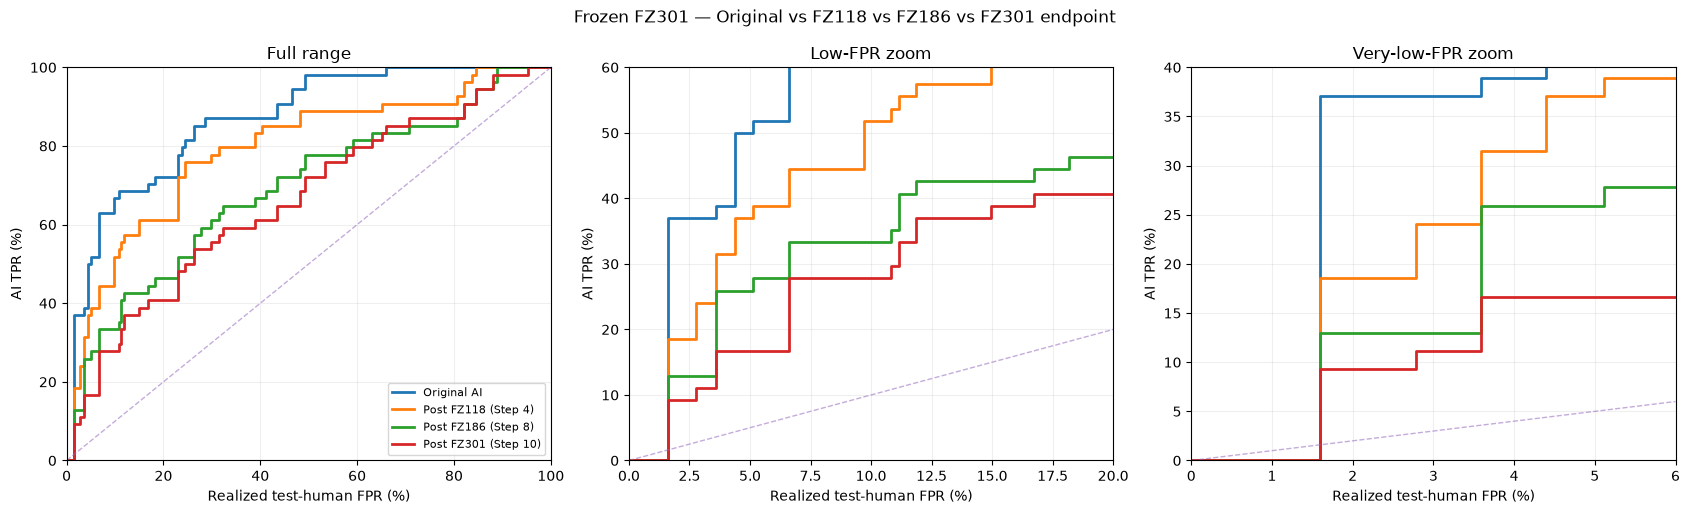

In [18]:
# Canonical four-stage staircase.
cm,hm,wc,wh=masks_weights(step10.domain)
cal=fz301.predict_proba(XR.loc[cm,F301])[:,1]
hs=fz301.predict_proba(XR.loc[hm,F301])[:,1]

summary=pd.DataFrame([{"stage":k,"AUROC":weighted_auc(hs,wh,v),"mean_AI_score":v.mean(),"median_AI_score":np.median(v)}
                      for k,v in stage_scores.items()])
display(summary);summary.to_csv(OUT/"canonical_stage_summary.csv",index=False)

st=staircase(cal,wc,hs,wh,stage_scores)
st.to_csv(OUT/"canonical_four_stage_TPR_staircase.csv",index=False)
plot_stair(st,list(stage_scores),"Frozen FZ301 — Original vs FZ118 vs FZ186 vs FZ301 endpoint",
           "C04e_FZ301_original_step4_step8_step10_TPR_staircase")


In [19]:
# Canonical four-stage summary: reuse previously accepted metrics exactly.

c04_summary=pd.read_csv(C04_RUN/"stage_summary.csv")
c04c_summary=pd.read_csv(STEP10_RUN/"stage_summary.csv")

summary=pd.DataFrame([
    {
        "stage":"Original AI",
        "AUROC":c04_summary.iloc[0].AUROC,
        "mean_AI_score":c04_summary.iloc[0].mean_AI_score,
        "median_AI_score":c04_summary.iloc[0].median_AI_score
    },
    {
        "stage":"Post FZ118 (Step 4)",
        "AUROC":c04_summary.iloc[1].AUROC,
        "mean_AI_score":c04_summary.iloc[1].mean_AI_score,
        "median_AI_score":c04_summary.iloc[1].median_AI_score
    },
    {
        "stage":"Post FZ186 (Step 8)",
        "AUROC":c04_summary.iloc[2].AUROC,
        "mean_AI_score":c04_summary.iloc[2].mean_AI_score,
        "median_AI_score":c04_summary.iloc[2].median_AI_score
    },
    {
        "stage":"Post FZ301 (Step 10)",
        "AUROC":c04c_summary.iloc[-1].AUROC,
        "mean_AI_score":c04c_summary.iloc[-1].mean_AI_score,
        "median_AI_score":c04c_summary.iloc[-1].median_AI_score
    }
])

display(summary)
summary.to_csv(OUT/"canonical_stage_summary.csv",index=False)

,stage,AUROC,mean_AI_score,median_AI_score
0,Original AI,0.875380,0.599424,0.596259
1,Post FZ118 (Step 4),0.801146,0.544962,0.541416
2,Post FZ186 (Step 8),0.699558,0.500605,0.478403
3,Post FZ301 (Step 10),0.671326,0.476821,0.459692


## Adaptive Camouflage

Choose 20 Step-10 texts uniformly at random with a fixed seed. Retrain a fresh clone of FZ301 on the original RAID training rows plus those 20 exposed Step-10 AI examples. Evaluate only on the remaining 34.

Each detector uses thresholds calibrated on the same fixed validation-human pool; realized FPR is measured on the same fixed test-human pool.


In [5]:
# Fixed random 20/34 split.
rng=np.random.default_rng(SEED)
adapt_idx=np.sort(rng.choice(len(step10),size=20,replace=False))
test_idx=np.setdiff1d(np.arange(len(step10)),adapt_idx)
split=step10[["case_id","source_id","domain"]].copy();split["role"]="test";split.loc[adapt_idx,"role"]="adaptation"
split.to_csv(OUT/"adaptive_split_20_34.csv",index=False)
print("20 adaptation / 34 test")
display(pd.crosstab(split.domain,split.role))
display(split.loc[split.role.eq("adaptation")].reset_index(drop=True))


20 adaptation / 34 test


role,adaptation,test
domain,,
abstracts,4,6
books,1,6
news,6,6
recipes,3,6
reddit,1,5
reviews,0,1
wiki,5,4


,case_id,source_id,domain,role
0,gate_0007,ai__raid:ae32af9e-d8dc-415d-bb9f-051981e11dd4,wiki,adaptation
1,gate_0015,ai__raid:cfb5728e-c896-4ed5-8173-f39be5ff5f97,abstracts,adaptation
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news,adaptation
3,gate_0018,ai__raid:6caeff0b-6fa7-4fea-9a48-342fe2d6b83b,recipes,adaptation
4,gate_0021,ai__raid:cf67eb69-444d-4e5f-a88b-da82d19f89a9,wiki,adaptation
5,gate_0023,ai__raid:7b6ca4a8-9f9f-4ede-a9ce-4d6ca52ac525,books,adaptation
6,gate_0027,ai__raid:f3cc8b87-5e7a-49cb-bc52-a57b28ce27d2,wiki,adaptation
7,gate_0030,ai__raid:fcc95fec-43c3-4885-86f5-8e310a8d552f,news,adaptation
8,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit,adaptation
9,gate_0048,ai__raid:b0d2e4eb-3c43-49ce-bfe1-9a6eafef8b02,news,adaptation


In [11]:
# Build/cache exact RAID FZ301 features, then retrain on RAID train + 20 exposed Step-10 samples.
import math
import re

# Adaptive retraining — self-contained, reuses cached RAID extensions.

raid=features_all.loc[features_all.dataset.eq("raid")].copy().reset_index(drop=True)
ext_cache=OUT/"raid_FZ301_extensions.parquet"
assert ext_cache.exists(),"RAID extension cache missing"

raid_ext=pd.read_parquet(ext_cache).set_index("source_id").loc[raid.source_id].reset_index(drop=True)
XR=pd.concat([raid[FEATURE_NAMES].reset_index(drop=True),raid_ext[EXT_NAMES]],axis=1)[F301]

# Reconstruct fixed random 20/34 split if necessary.
if "adapt_idx" not in globals():
    rng=np.random.default_rng(SEED)
    adapt_idx=np.sort(rng.choice(len(step10),size=20,replace=False))
    test_idx=np.setdiff1d(np.arange(len(step10)),adapt_idx)

# Compute only the 54 Step-10 FZ301 vectors if not already in memory.
if "X_step10" not in globals():
    X_step10=f301_frame(step10,"Step10")

train_mask=raid.split.eq("train").to_numpy()
X_train=XR.loc[train_mask,F301].reset_index(drop=True)
y_train=raid.loc[train_mask,"label"].astype(int).to_numpy()

X_aug=pd.concat([X_train,X_step10.iloc[adapt_idx].reset_index(drop=True)],ignore_index=True)
y_aug=np.r_[y_train,np.ones(len(adapt_idx),dtype=int)]

adaptive_fz301=clone(fz301)
adaptive_fz301.fit(X_aug,y_aug)

with (OUT/"FZ301_adaptive_20.pkl").open("wb") as f:
    pickle.dump(adaptive_fz301,f)

print("Original train:",len(X_train),"+ exposed:",len(adapt_idx),"=",len(X_aug))
print("Held out:",len(test_idx))

Step10 18 / 54
Step10 36 / 54
Step10 54 / 54
Original train: 1272 + exposed: 20 = 1292
Held out: 34


,detector,AUROC,mean_AI_score,median_AI_score,AUROC_change_vs_frozen
0,Frozen FZ301,0.677416,0.492403,0.484809,0.000000
1,Retrained FZ301 (+20 Step-10 AI),0.707792,0.514390,0.500258,0.030377


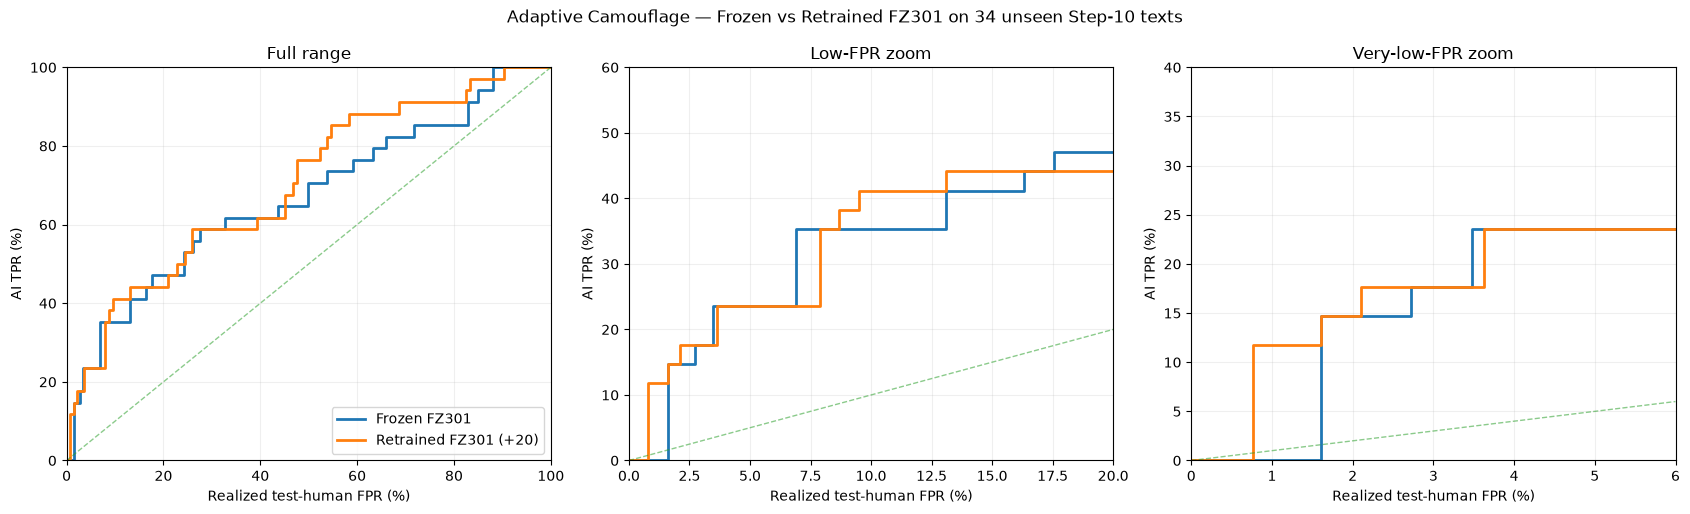

In [13]:
# Adaptive Camouflage evaluation — frozen vs retrained FZ301 on the same unseen 34.

from sklearn.metrics import roc_curve, auc

# Restore RAID/XR from cache if needed.
if "raid" not in globals():
    raid=features_all.loc[features_all.dataset.eq("raid")].copy().reset_index(drop=True)
if "XR" not in globals():
    ext_cache=OUT/"raid_FZ301_extensions.parquet"
    raid_ext=pd.read_parquet(ext_cache).set_index("source_id").loc[raid.source_id].reset_index(drop=True)
    XR=pd.concat([raid[FEATURE_NAMES].reset_index(drop=True),raid_ext[EXT_NAMES]],axis=1)[F301]

# Restore fixed 20/34 split if needed.
if "adapt_idx" not in globals():
    rng=np.random.default_rng(SEED)
    adapt_idx=np.sort(rng.choice(len(step10),20,replace=False))
    test_idx=np.setdiff1d(np.arange(len(step10)),adapt_idx)

held=step10.iloc[test_idx].reset_index(drop=True)
X_held=X_step10.iloc[test_idx].reset_index(drop=True)

def masks_weights(domains):
    mix=pd.Series(domains).value_counts(normalize=True)
    def mask(split): return (raid.split.eq(split)&raid.label.eq(0)&raid.domain.isin(mix.index)).to_numpy()
    def weights(m):
        g=raid.loc[m,"domain"]; counts=g.value_counts()
        w=np.array([mix[x]/counts[x] for x in g],float)
        assert np.isclose(w.sum(),1); return w
    cm,hm=mask("validation"),mask("test")
    return cm,hm,weights(cm),weights(hm)

def weighted_auc(hs,wh,ais):
    y=np.r_[np.zeros(len(hs)),np.ones(len(ais))]
    s=np.r_[hs,ais]; w=np.r_[wh,np.ones(len(ais))/len(ais)]
    fpr,tpr,_=roc_curve(y,s,sample_weight=w,drop_intermediate=False)
    return auc(fpr,tpr)

def staircase(cal,wc,hs,wh,ais):
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    return pd.DataFrame({
        "threshold":cuts,
        "calibration_FPR":[wc[cal>c].sum() for c in cuts],
        "test_FPR":[wh[hs>c].sum() for c in cuts],
        "TPR":[np.mean(ais>c) for c in cuts]
    })

cm34,hm34,wc34,wh34=masks_weights(held.domain)

normal_cal=fz301.predict_proba(XR.loc[cm34,F301])[:,1]
adapt_cal=adaptive_fz301.predict_proba(XR.loc[cm34,F301])[:,1]
normal_h=fz301.predict_proba(XR.loc[hm34,F301])[:,1]
adapt_h=adaptive_fz301.predict_proba(XR.loc[hm34,F301])[:,1]
normal_ai=fz301.predict_proba(X_held)[:,1]
adapt_ai=adaptive_fz301.predict_proba(X_held)[:,1]

ad_summary=pd.DataFrame([
    {"detector":"Frozen FZ301","AUROC":weighted_auc(normal_h,wh34,normal_ai),
     "mean_AI_score":normal_ai.mean(),"median_AI_score":np.median(normal_ai)},
    {"detector":"Retrained FZ301 (+20 Step-10 AI)","AUROC":weighted_auc(adapt_h,wh34,adapt_ai),
     "mean_AI_score":adapt_ai.mean(),"median_AI_score":np.median(adapt_ai)}
])
ad_summary["AUROC_change_vs_frozen"]=ad_summary.AUROC-ad_summary.iloc[0].AUROC
display(ad_summary)
ad_summary.to_csv(OUT/"adaptive_camouflage_summary.csv",index=False)

ns=staircase(normal_cal,wc34,normal_h,wh34,normal_ai)
rs=staircase(adapt_cal,wc34,adapt_h,wh34,adapt_ai)

def step_at(x,y,grid):
    o=np.argsort(x); x=np.asarray(x)[o]; y=np.asarray(y)[o]
    i=np.searchsorted(x,grid,side="right")-1
    return y[np.clip(i,0,len(y)-1)]

grid=np.unique(np.r_[ns.test_FPR,rs.test_FPR])
cmp=pd.DataFrame({
    "test_FPR":grid,
    "Frozen FZ301":step_at(ns.test_FPR,ns.TPR,grid),
    "Retrained FZ301 (+20)":step_at(rs.test_FPR,rs.TPR,grid)
})

fig,axs=plt.subplots(1,3,figsize=(17,5.2))
panels=[((0,100),(0,100),"Full range"),((0,20),(0,60),"Low-FPR zoom"),((0,6),(0,40),"Very-low-FPR zoom")]
for ax,(xlim,ylim,title) in zip(axs,panels):
    ax.step(cmp.test_FPR*100,cmp["Frozen FZ301"]*100,where="post",lw=2,label="Frozen FZ301")
    ax.step(cmp.test_FPR*100,cmp["Retrained FZ301 (+20)"]*100,where="post",lw=2,label="Retrained FZ301 (+20)")
    hi=min(xlim[1],ylim[1]); ax.plot([0,hi],[0,hi],"--",lw=1,alpha=.55)
    ax.set(xlim=xlim,ylim=ylim,xlabel="Realized test-human FPR (%)",ylabel="AI TPR (%)",title=title); ax.grid(alpha=.2)

axs[0].legend(loc="lower right")
fig.suptitle("Adaptive Camouflage — Frozen vs Retrained FZ301 on 34 unseen Step-10 texts")
fig.tight_layout()

for folder in [OUT,FIG]:
    fig.savefig(folder/"C04e_FZ301_adaptive_camouflage_20_34_TPR_staircase.pdf",bbox_inches="tight")
    fig.savefig(folder/"C04e_FZ301_adaptive_camouflage_20_34_TPR_staircase.png",dpi=300,bbox_inches="tight")
plt.show()

ns.to_csv(OUT/"adaptive_frozen_staircase.csv",index=False)
rs.to_csv(OUT/"adaptive_retrained_staircase.csv",index=False)
cmp.to_csv(OUT/"adaptive_comparison_TPR_staircase.csv",index=False)

In [14]:
case_scores=held[["case_id","source_id","domain"]].copy()
case_scores["Frozen_FZ301_score"]=normal_ai;case_scores["Retrained_FZ301_score"]=adapt_ai
case_scores["score_change"]=adapt_ai-normal_ai
case_scores.to_csv(OUT/"adaptive_heldout34_scores.csv",index=False)
display(case_scores.sort_values("score_change",ascending=False).reset_index(drop=True))

contract={"name":"C04e_FZ301_wrapup_adaptive_camouflage","seed":SEED,"adaptation_n":20,"test_n":34,
          "adaptive_fit":"regular RAID train + 20 random exposed Step-10 AI examples, unit weight",
          "thresholds":"detector-specific calibration on fixed validation humans","endpoint":"Step 10 CARDINAL; Step 10.9 excluded",
          "c04_run":str(C04_RUN.relative_to(ROOT)),"step10_run":str(STEP10_RUN.relative_to(ROOT)),
          "sklearn":sklearn.__version__,"spacy":nlp.meta}
(OUT/"contract.json").write_text(json.dumps(contract,indent=2,default=str))
print("Saved:",OUT.relative_to(ROOT))


,case_id,source_id,domain,Frozen_FZ301_score,Retrained_FZ301_score,score_change
0,gate_0089,ai__raid:788e4594-960c-4621-8b5e-6f82b7552d7b,recipes,0.322917,0.393407,0.070490
1,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books,0.461353,0.530627,0.069274
2,gate_0079,ai__raid:48ea9a1e-7e86-41ee-a3bb-4675af0442ef,abstracts,0.305448,0.367345,0.061896
3,gate_0086,ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,wiki,0.443972,0.504904,0.060932
4,gate_0076,ai__raid:90cd9493-2714-47d7-b052-f3c621294322,news,0.518623,0.577782,0.059159
5,gate_0022,ai__raid:4c4676d5-c143-448c-b058-9c360b04d900,abstracts,0.349593,0.404827,0.055234
6,gate_0081,ai__raid:723a39e2-9540-4faa-b682-d608457dfde1,recipes,0.300933,0.345127,0.044194
7,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,0.514412,0.554423,0.040011
8,gate_0088,ai__raid:6d37b523-501f-412e-a18b-645d8e3653a6,news,0.403189,0.443177,0.039987
9,gate_0075,ai__raid:0a9dc4af-7338-49c0-b3d9-3a1a3cf1606f,books,0.383994,0.423679,0.039685


Saved: results/causal/C04e_FZ301_wrapup_adaptive_camouflage
